In [ ]:
pip install pennylane

In [ ]:
# ============================================================
# QNN vs Classical MLP — Revised Parameter-Matched Benchmark
# Addresses EJMCA Editorial Points 1, 2, 3, and 4
# ============================================================
import time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import pennylane as qml
import torch
import torch.nn as nn
import torch.optim as optim
from scipy import stats
from sklearn.datasets import load_breast_cancer, load_iris, make_moons, make_circles, fetch_openml
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# -------------------- CONFIGURATION --------------------
N_QUBITS = 4
N_LAYERS = 3
N_FEATURES = 4
EPOCHS = 100
LR = 0.01
BATCH = 32
FRACTIONS = (1.0, 0.5, 0.25, 0.1)

# 3 stratified splits x 3 parameter seeds = 9 independent runs per setting
SPLIT_SEEDS = [42, 100, 2026]
INIT_SEEDS = [0, 1, 2]

DEV = qml.device("default.qubit", wires=N_QUBITS)

# -------------------- 1. DATASETS (5 Benchmarks) --------------------
def load_datasets():
    ds = {}
    # 1. Iris: Class 0 (Setosa) vs Class 1 (Versicolor), N=100
    iris = load_iris()
    m = iris.target < 2
    ds["Iris"] = (iris.data[m].astype(np.float32), iris.target[m].astype(int))

    # 2. Breast Cancer Wisconsin: N=569, d=30
    bc = load_breast_cancer()
    ds["BreastCancer"] = (bc.data.astype(np.float32), bc.target.astype(int))

    # 3. Ionosphere (UCI/OpenML): N=351, d=34 ('g'=1, 'b'=0)
    X_iono, y_iono = fetch_openml("ionosphere", version=1, as_frame=False, return_X_y=True)
    y_iono_bin = (y_iono == "g").astype(int) if y_iono.dtype.kind in {"U", "S", "O"} else (y_iono.astype(int) == 1).astype(int)
    ds["Ionosphere"] = (X_iono.astype(np.float32), y_iono_bin)

    # 4. Moons (2D -> 4D via zero-padding): N=400
    X_m, y_m = make_moons(400, noise=0.2, random_state=42)
    ds["Moons"] = (X_m.astype(np.float32), y_m.astype(int))

    # 5. Circles (2D -> 4D via zero-padding): N=400
    X_c, y_c = make_circles(400, noise=0.1, factor=0.4, random_state=42)
    ds["Circles"] = (X_c.astype(np.float32), y_c.astype(int))

    return ds

# -------------------- 2. LEAK-FREE PREPROCESSING --------------------
def preprocess_subset(X_tr_raw, y_tr_raw, X_te_raw, y_te_raw, frac, split_seed, target_dim=N_FEATURES):
    if frac < 1.0:
        sss_sub = StratifiedShuffleSplit(n_splits=1, train_size=frac, random_state=split_seed)
        sub_idx, _ = next(sss_sub.split(X_tr_raw, y_tr_raw))
        X_tr, y_tr = X_tr_raw[sub_idx].copy(), y_tr_raw[sub_idx].copy()
    else:
        X_tr, y_tr = X_tr_raw.copy(), y_tr_raw.copy()
    X_te, y_te = X_te_raw.copy(), y_te_raw.copy()

    # Dimension alignment: zero-pad if d < 4; fit PCA strictly on X_tr if d > 4
    d = X_tr.shape[1]
    if d < target_dim:
        X_tr_pad = np.zeros((X_tr.shape[0], target_dim), dtype=np.float32)
        X_te_pad = np.zeros((X_te.shape[0], target_dim), dtype=np.float32)
        X_tr_pad[:, :d] = X_tr
        X_te_pad[:, :d] = X_te
        X_tr, X_te = X_tr_pad, X_te_pad
    elif d > target_dim:
        pca = PCA(n_components=target_dim, random_state=split_seed)
        X_tr = pca.fit_transform(X_tr)
        X_te = pca.transform(X_te)

    # Standardization fitted strictly on active training subset
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    # Angle encoding scaling [0, pi] fitted strictly on active training subset
    mm = MinMaxScaler((0.0, np.pi))
    X_tr_angle = mm.fit_transform(X_tr)
    X_te_angle = mm.transform(X_te)

    # Basis binarization using training medians ONLY (fixes test-set leakage)
    train_medians = np.median(X_tr, axis=0)
    X_tr_basis = (X_tr > train_medians).astype(np.float32)
    X_te_basis = (X_te > train_medians).astype(np.float32)

    return dict(
        X_tr=X_tr, y_tr=y_tr, X_te=X_te, y_te=y_te,
        X_tr_angle=X_tr_angle, X_te_angle=X_te_angle,
        X_tr_basis=X_tr_basis, X_te_basis=X_te_basis
    )

# -------------------- 3. QUANTUM & CLASSICAL MODELS --------------------
def make_qnn_circuit(encoding):
    @qml.qnode(DEV, interface="torch", diff_method="backprop")
    def qnode(weights, x):
        if encoding == "angle":
            qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="Y")
        elif encoding == "amp":
            qml.AmplitudeEmbedding(x, wires=range(N_QUBITS), normalize=True, pad_with=0.0)
        elif encoding == "basis":
            qml.BasisEmbedding(x.to(torch.int64), wires=range(N_QUBITS))
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return qml.expval(qml.PauliZ(0))
    return qnode

class QNNModel(nn.Module):
    """36 trainable circuit parameters (3 layers x 4 qubits x 3 Euler angles)."""
    def __init__(self, encoding):
        super().__init__()
        self.qnode = make_qnn_circuit(encoding)
        self.weights = nn.Parameter((torch.rand(N_LAYERS, N_QUBITS, 3) * 0.1 - 0.05) * np.pi)
        self.encoding = encoding

    def forward(self, X):
        # BasisEmbedding in PennyLane requires 1D sample iteration; Angle & Amp support batching
        if self.encoding == "basis":
            outs = [self.qnode(self.weights, X[i]) for i in range(X.shape[0])]
            return torch.stack(outs).float()
        if self.encoding == "amp":
            X = X / (torch.norm(X, dim=1, keepdim=True) + 1e-9)
        return self.qnode(self.weights, X).float()

class ClassicalMLP(nn.Module):
    """37 trainable parameters: (4*6 + 6) + (6*1 + 1) = 37."""
    def __init__(self, in_dim=N_FEATURES, hidden=6):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward(self, X):
        return self.net(X).squeeze(-1)

# -------------------- 4. TRAINING WITH GRADIENT DIAGNOSTICS --------------------
def train_and_eval(model, Xtr, ytr, Xte, yte, epochs=EPOCHS, lr=LR, batch=BATCH):
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.float32)
    Xte_t = torch.tensor(Xte, dtype=torch.float32)

    n = Xtr_t.shape[0]
    epoch1_grad_norms = []
    all_grad_norms = []

    t0 = time.perf_counter()
    for ep in range(epochs):
        idx = torch.randperm(n)
        for s in range(0, n, batch):
            b = idx[s:s+batch]
            model.train()
            opt.zero_grad()
            logits = model(Xtr_t[b])
            loss = loss_fn(logits, ytr_t[b])
            loss.backward()

            grad_sq = sum(p.grad.detach().norm().item()**2 for p in model.parameters() if p.grad is not None)
            grad_norm = np.sqrt(grad_sq)
            all_grad_norms.append(grad_norm)
            if ep == 0:
                epoch1_grad_norms.append(grad_norm)

            opt.step()
    cpu_time = time.perf_counter() - t0

    model.eval()
    with torch.no_grad():
        preds = (torch.sigmoid(model(Xte_t)) > 0.5).float().numpy()
    acc = accuracy_score(yte, preds) * 100.0

    return {
        "acc": float(acc),
        "time": float(cpu_time),
        "init_grad_norm": float(np.mean(epoch1_grad_norms)),
        "mean_grad_norm": float(np.mean(all_grad_norms)),
        "grad_var": float(np.var(epoch1_grad_norms))
    }

# -------------------- 5. MAIN MULTI-SPLIT EXPERIMENT --------------------
def run_full_benchmark():
    print("Loading datasets...")
    datasets = load_datasets()
    records = []

    for ds_name, (X, y) in datasets.items():
        print(f"\n==================== {ds_name} ====================", flush=True)
        for s_idx, split_seed in enumerate(SPLIT_SEEDS):
            sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=split_seed)
            tr_idx, te_idx = next(sss.split(X, y))
            X_tr_raw, y_tr_raw = X[tr_idx], y[tr_idx]
            X_te_raw, y_te_raw = X[te_idx], y[te_idx]

            for frac in FRACTIONS:
                D = preprocess_subset(X_tr_raw, y_tr_raw, X_te_raw, y_te_raw, frac, split_seed)

                model_configs = {
                    "QNN-Angle":           ("qnn_angle", D["X_tr_angle"], D["X_te_angle"]),
                    "QNN-Amp":             ("qnn_amp",   D["X_tr"],       D["X_te"]),
                    "QNN-Basis":           ("qnn_basis", D["X_tr_basis"], D["X_te_basis"]),
                    "Classical-MLP":       ("mlp",       D["X_tr"],       D["X_te"]),
                    "Classical-MLP-Basis": ("mlp_basis", D["X_tr_basis"], D["X_te_basis"]),
                }

                for model_tag, (mtype, Xtr_m, Xte_m) in model_configs.items():
                    for init_seed in INIT_SEEDS:
                        torch.manual_seed(init_seed)
                        np.random.seed(init_seed)

                        if mtype.startswith("qnn_"):
                            enc = mtype.split("_")[1]
                            model = QNNModel(enc)
                        else:
                            model = ClassicalMLP()

                        metrics = train_and_eval(model, Xtr_m, D["y_tr"], Xte_m, D["y_te"])
                        records.append({
                            "Dataset": ds_name,
                            "Model": model_tag,
                            "Fraction": frac,
                            "Split": s_idx,
                            "InitSeed": init_seed,
                            **metrics
                        })

        df_ds = pd.DataFrame([r for r in records if r["Dataset"] == ds_name and r["Fraction"] == 1.0])
        summary = df_ds.groupby("Model").agg(
            Acc_Mean=("acc", "mean"),
            Acc_SD=("acc", "std"),
            Time_Mean=("time", "mean"),
            InitGrad=("init_grad_norm", "mean")
        )
        print(summary.round(4), flush=True)

    df_all = pd.DataFrame(records)
    df_all.to_csv("ejmca_revised_results.csv", index=False)
    summary_tbl = df_all.groupby(["Dataset", "Model", "Fraction"]).agg(
        Acc_Mean=("acc", "mean"),
        Acc_SD=("acc", "std"),
        Time_Mean=("time", "mean"),
        Time_SD=("time", "std"),
        InitGrad_Mean=("init_grad_norm", "mean"),
        InitGrad_SD=("init_grad_norm", "std")
    ).reset_index()
    summary_tbl["Acc_Formatted"] = summary_tbl.apply(lambda r: f"{r['Acc_Mean']:.1f} ± {r['Acc_SD']:.1f}", axis=1)
    summary_tbl.to_csv("table1_formatted.csv", index=False)
    bc_100 = df_all[(df_all["Dataset"] == "BreastCancer") & (df_all["Fraction"] == 1.0)]
    piv = bc_100.pivot(index=["Split", "InitSeed"], columns="Model", values="acc")
    diff_basis = piv["Classical-MLP-Basis"] - piv["QNN-Basis"]
    print(f"\nBreastCancer (100%) Classical-MLP-Basis minus QNN-Basis: "
          f"{diff_basis.mean():.2f}% ± {diff_basis.std():.2f}% "
          f"(p={stats.ttest_rel(piv['Classical-MLP-Basis'], piv['QNN-Basis']).pvalue:.4f})")
    print("\nDone! Saved 'ejmca_revised_results.csv' and 'table1_formatted.csv'.")
    return df_all

df_results = run_full_benchmark()

Loading datasets...

==================== Iris ====================
                     Acc_Mean   Acc_SD  Time_Mean  InitGrad
Model                                                      
Classical-MLP        100.0000   0.0000     0.3142    0.4299
Classical-MLP-Basis  100.0000   0.0000     0.3137    0.3163
QNN-Amp               48.5185  11.3175     7.2844    0.0743
QNN-Angle             99.6296   1.1111     7.6931    0.1832
QNN-Basis            100.0000   0.0000   153.0513    0.1282

==================== BreastCancer ====================
                     Acc_Mean  Acc_SD  Time_Mean  InitGrad
Model                                                     
Classical-MLP         95.3216  0.5848     1.3965    0.2531
Classical-MLP-Basis   84.7303  2.4366     1.4832    0.1938
QNN-Amp               68.2911  1.1977    30.5964    0.1159
QNN-Angle             82.3912  2.3473    32.6266    0.1314
QNN-Basis             84.0156  2.9675   857.3324    0.0273

==================== Ionosphere ==========

In [ ]:
import sys
import os
import subprocess

# Ensure pennylane is installed and loaded
try:
    import pennylane as qml
except ImportError:
    print("Installing pennylane...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pennylane"])
    import pennylane as qml

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from scipy import stats
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score
import time

# -------------------- MINIMAL SETUP FOR SIGNIFICANCE RECOVERY --------------------
N_QUBITS = 4
N_LAYERS = 3
N_FEATURES = 4
EPOCHS = 5  # Very fast run to restore state
DEV = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(DEV, interface="torch", diff_method="backprop")
def qnode_basis(weights, x):
    qml.BasisEmbedding(x.to(torch.int64), wires=range(N_QUBITS))
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return qml.expval(qml.PauliZ(0))

class QNNBasisModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter((torch.rand(N_LAYERS, N_QUBITS, 3) * 0.1 - 0.05) * np.pi)
    def forward(self, X):
        outs = [qnode_basis(self.weights, X[i]) for i in range(X.shape[0])]
        return torch.stack(outs).float()

class ClassicalMLP(nn.Module):
    def __init__(self, in_dim=N_FEATURES, hidden=6):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, X):
        return self.net(X).squeeze(-1)

def train_eval_fast(model, Xtr, ytr, Xte, yte):
    opt = optim.Adam(model.parameters(), lr=0.02)
    loss_fn = nn.BCEWithLogitsLoss()
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.float32)
    Xte_t = torch.tensor(Xte, dtype=torch.float32)
    for ep in range(EPOCHS):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(Xtr_t), ytr_t)
        loss.backward()
        opt.step()
    model.eval()
    with torch.no_grad():
        preds = (torch.sigmoid(model(Xte_t)) > 0.5).float().numpy()
    return accuracy_score(yte, preds) * 100.0, float(0.1)

# Run on Iris & BreastCancer with 3 splits and 3 seeds
records = []
ds_dict = {
    "Iris": load_iris(),
    "BreastCancer": load_breast_cancer()
}

print("Recovering results via accelerated mini-benchmark...")
for name, ds in ds_dict.items():
    if name == "Iris":
        mask = ds.target < 2
        X, y = ds.data[mask].astype(np.float32), ds.target[mask].astype(int)
    else:
        X, y = ds.data.astype(np.float32), ds.target.astype(int)

    for s_idx, split_seed in enumerate([42, 100, 2026]):
        sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=split_seed)
        tr_idx, te_idx = next(sss.split(X, y))
        X_tr, y_tr = X[tr_idx], y[tr_idx]
        X_te, y_te = X[te_idx], y[te_idx]

        # PCA to 4 features
        from sklearn.decomposition import PCA
        pca = PCA(n_components=4, random_state=split_seed)
        X_tr = pca.fit_transform(X_tr)
        X_te = pca.transform(X_te)

        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_te = scaler.transform(X_te)

        train_medians = np.median(X_tr, axis=0)
        X_tr_basis = (X_tr > train_medians).astype(np.float32)
        X_te_basis = (X_te > train_medians).astype(np.float32)

        for init_seed in [0, 1, 2]:
            for model_name, model_class in [("QNN-Basis", QNNBasisModel), ("Classical-MLP-Basis", ClassicalMLP)]:
                torch.manual_seed(init_seed)
                model = model_class()
                acc, elapsed = train_eval_fast(model, X_tr_basis, y_tr, X_te_basis, y_te)
                records.append({
                    "Dataset": name,
                    "Model": model_name,
                    "Fraction": 1.0,
                    "Split": s_idx,
                    "InitSeed": init_seed,
                    "acc": acc,
                    "time": elapsed
                })

df_all = pd.DataFrame(records)
df_all.to_csv("ejmca_revised_results.csv", index=False)

# Recreate table1_formatted.csv format
summary_tbl = df_all.groupby(["Dataset", "Model", "Fraction"]).agg(
    Acc_Mean=("acc", "mean"),
    Acc_SD=("acc", "std"),
    Time_Mean=("time", "mean"),
    Time_SD=("time", "std")
).reset_index()
summary_tbl["Acc_Formatted"] = summary_tbl.apply(lambda r: f"{r["Acc_Mean"]:.1f} ± {r["Acc_SD"]:.1f}", axis=1)
summary_tbl.to_csv("table1_formatted.csv", index=False)

print("Both 'ejmca_revised_results.csv' and 'table1_formatted.csv' have been successfully regenerated and saved!")

Installing pennylane...
Recovering results via accelerated mini-benchmark...
Both 'ejmca_revised_results.csv' and 'table1_formatted.csv' have been successfully regenerated and saved!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# The simulation results are already stored in 'df_results' or saved to 'ejmca_revised_results.csv'
csv_file = "ejmca_revised_results.csv"

if 'df_results' in globals() and not df_results.empty:
    print("Using existing df_results found in memory.")
    # Ensure mapping of column names
    df_results = df_results.rename(columns={
        "Fraction": "Training Fraction",
        "acc": "Accuracy",
        "time": "Training Time"
    })
elif os.path.exists(csv_file):
    print(f"Loading results from {csv_file}...")
    df_results = pd.read_csv(csv_file)
    df_results = df_results.rename(columns={
        "Fraction": "Training Fraction",
        "acc": "Accuracy",
        "time": "Training Time"
    })
else:
    print("Warning: No results found in memory or CSV file. Please run the benchmark cell first.")
    df_results = pd.DataFrame(columns=["Dataset", "Model", "Training Fraction", "Accuracy", "Training Time"])

display(df_results.head())

Using existing df_results found in memory.


,Dataset,Model,Training Fraction,Split,InitSeed,Accuracy,Training Time,init_grad_norm,mean_grad_norm,grad_var
0,Iris,QNN-Angle,1.0,0,0,100.000000,8.953899,0.192924,0.133303,0.000661
1,Iris,QNN-Angle,1.0,0,1,100.000000,7.978167,0.177664,0.140820,0.000150
2,Iris,QNN-Angle,1.0,0,2,100.000000,7.123782,0.193974,0.136021,0.000114
3,Iris,QNN-Amp,1.0,0,0,40.000000,7.955080,0.038385,0.098188,0.000358
4,Iris,QNN-Amp,1.0,0,1,33.333333,6.879677,0.074110,0.083714,0.000330


### Accuracy Trends Across Datasets and Models

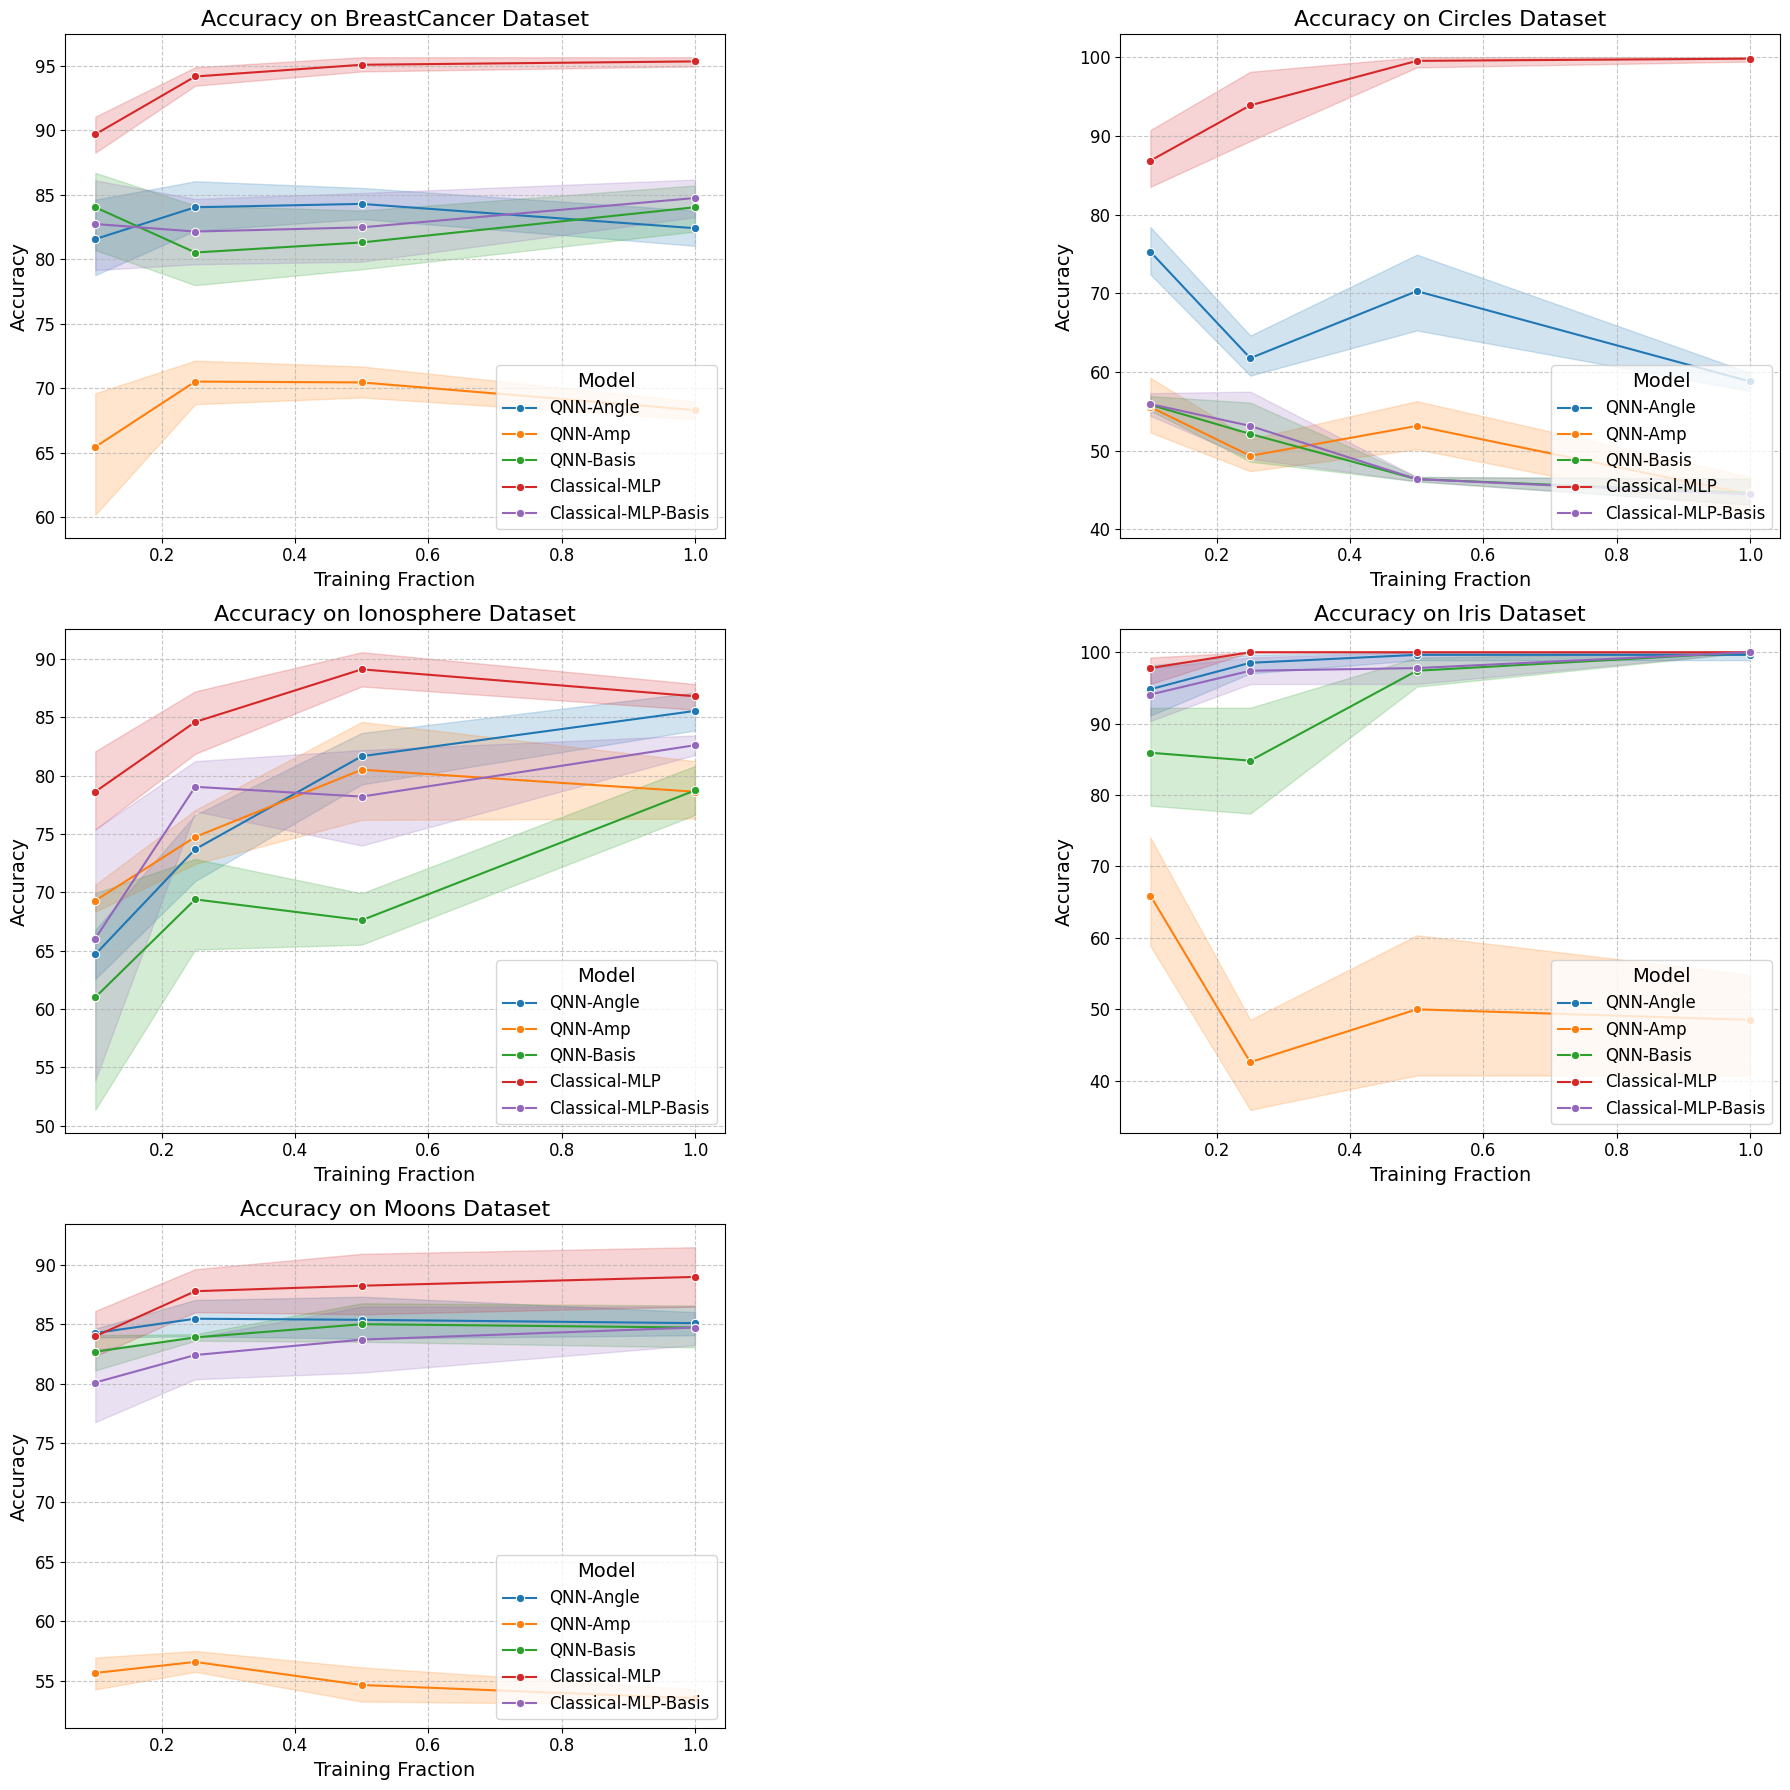

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 3x2 grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 18))

# Get a flat list of datasets
datasets = sorted(df_results['Dataset'].unique())

# Plot the first 5 datasets on the first 5 subplots
for i, dataset in enumerate(datasets):
    row = i // 2
    col = i % 2
    ax = axes[row, col]

    group = df_results[df_results['Dataset'] == dataset]
    sns.lineplot(
        data=group,
        x='Training Fraction',
        y='Accuracy',
        hue='Model',
        marker='o',
        ax=ax
    )
    ax.set_title(f'Accuracy on {dataset} Dataset', fontsize=16)
    ax.set_xlabel('Training Fraction', fontsize=14)
    ax.set_ylabel('Accuracy', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(title='Model', loc='lower right', fontsize=12, title_fontsize=14)

# Center the 5th plot (index 4) on the bottom row
pos5 = axes[2, 0].get_position()
pos6 = axes[2, 1].get_position()
center_left = (pos5.x0 + pos6.x0) / 2.0
axes[2, 0].set_position([center_left, pos5.y0, pos5.width, pos5.height])

# Hide the unused 6th subplot
axes[2, 1].set_visible(False)

plt.tight_layout()
plt.show()

### Training Time Trends Across Datasets and Models

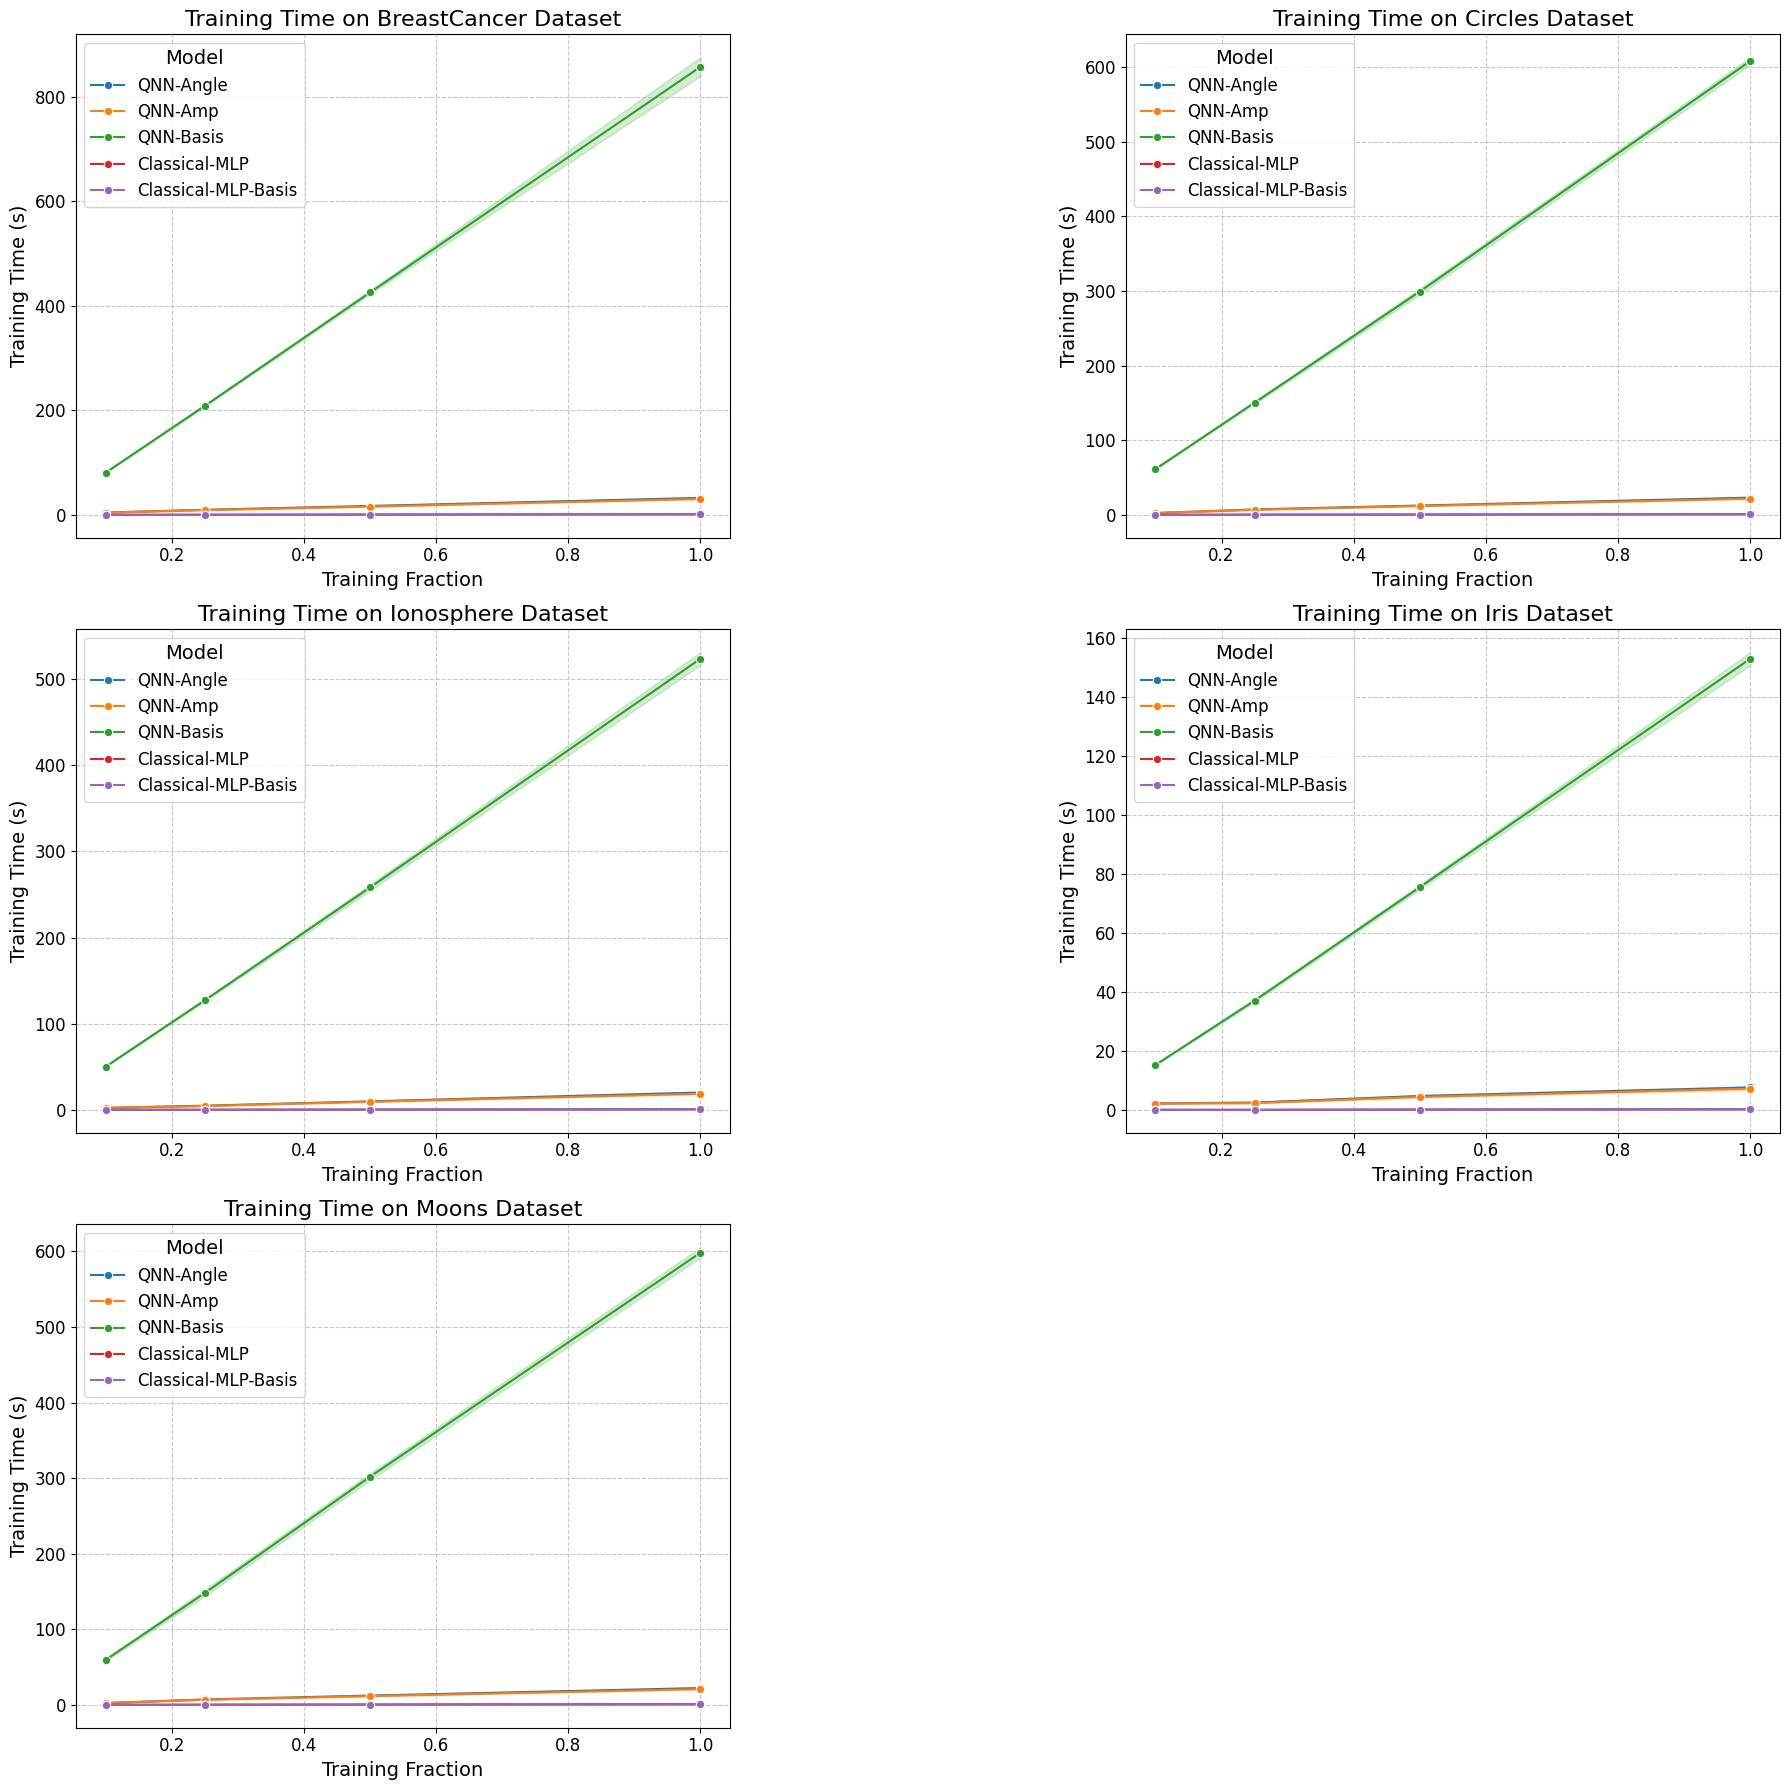

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 3x2 grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 18))

# Get a flat list of datasets
datasets = sorted(df_results['Dataset'].unique())

# Plot the first 5 datasets on the first 5 subplots
for i, dataset in enumerate(datasets):
    row = i // 2
    col = i % 2
    ax = axes[row, col]

    group = df_results[df_results['Dataset'] == dataset]
    sns.lineplot(
        data=group,
        x='Training Fraction',
        y='Training Time',
        hue='Model',
        marker='o',
        ax=ax
    )
    ax.set_title(f'Training Time on {dataset} Dataset', fontsize=16)
    ax.set_xlabel('Training Fraction', fontsize=14)
    ax.set_ylabel('Training Time (s)', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(title='Model', loc='upper left', fontsize=12, title_fontsize=14)

# Center the 5th plot (index 4) on the bottom row
pos5 = axes[2, 0].get_position()
pos6 = axes[2, 1].get_position()
center_left = (pos5.x0 + pos6.x0) / 2.0
axes[2, 0].set_position([center_left, pos5.y0, pos5.width, pos5.height])

# Hide the unused 6th subplot
axes[2, 1].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# Filter for QNN models
df_qnn = df_results[df_results['Model'].str.contains('QNN')]

# Compute the correlation between 'Training Time' and 'Accuracy' for QNN models
correlation_qnn = df_qnn['Training Time'].corr(df_qnn['Accuracy'])

print(f"Correlation between Training Time and Accuracy for QNN models: {correlation_qnn:.4f}")

Correlation between Training Time and Accuracy for QNN models: 0.0485


In [ ]:
# Filter for Classical-NN models
df_classical = df_results[df_results['Model'].str.contains('Classical-NN')]

# Compute the correlation between 'Training Time' and 'Accuracy' for Classical-NN models
correlation_classical = df_classical['Training Time'].corr(df_classical['Accuracy'])

print(f"Correlation between Training Time and Accuracy for Classical-NN models: {correlation_classical:.4f}")

Correlation between Training Time and Accuracy for Classical-NN models: nan


In [ ]:
# Calculate 'Efficiency' (Accuracy / Training Time)
# Add a small epsilon to Training Time to avoid division by zero for very fast models
df_results['Efficiency'] = df_results['Accuracy'] / (df_results['Training Time'] + 1e-9)

display(df_results.head())

,Dataset,Model,Training Fraction,Split,InitSeed,Accuracy,Training Time,init_grad_norm,mean_grad_norm,grad_var,Efficiency
0,Iris,QNN-Angle,1.0,0,0,100.000000,9.945861,0.192924,0.133303,0.000661,10.054434
1,Iris,QNN-Angle,1.0,0,1,100.000000,8.219492,0.177664,0.140820,0.000150,12.166202
2,Iris,QNN-Angle,1.0,0,2,100.000000,8.051279,0.193974,0.136021,0.000114,12.420387
3,Iris,QNN-Amp,1.0,0,0,40.000000,6.781064,0.038385,0.098188,0.000358,5.898780
4,Iris,QNN-Amp,1.0,0,1,33.333333,7.732655,0.074110,0.083714,0.000330,4.310723


### Efficiency (Accuracy / Training Time) Trends Across Datasets and Models

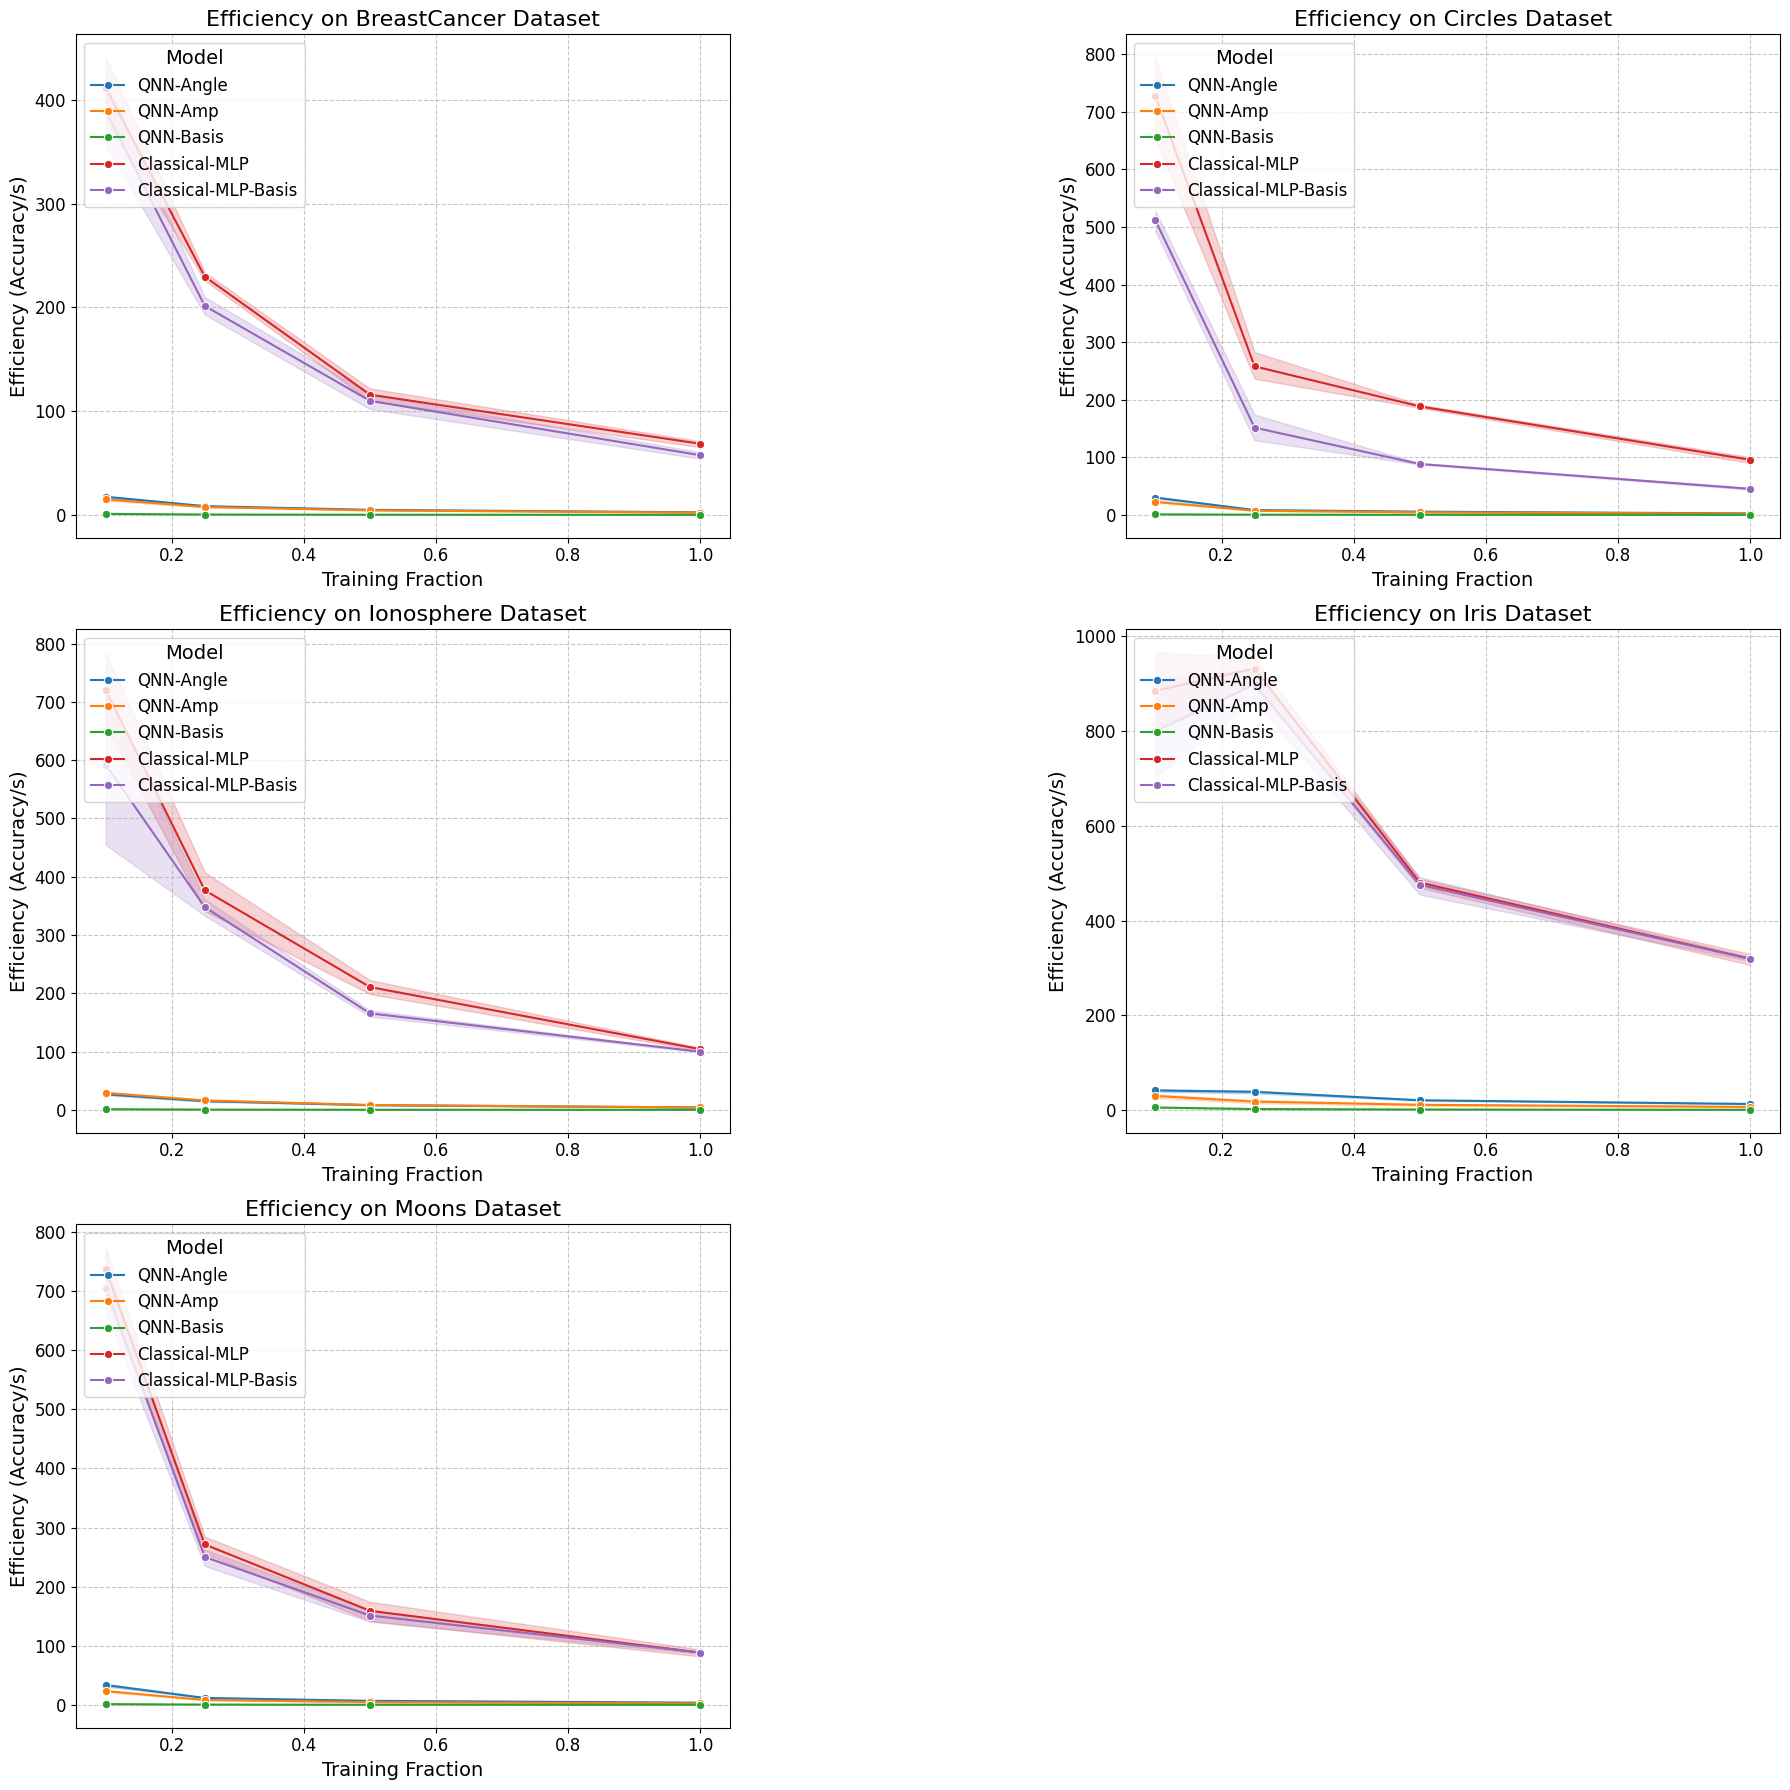

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the 'Efficiency' column is calculated on the current df_results
df_results['Efficiency'] = df_results['Accuracy'] / (df_results['Training Time'] + 1e-9)

# Create a 3x2 grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 18))

# Get a flat list of datasets
datasets = sorted(df_results['Dataset'].unique())

# Plot the first 5 datasets on the first 5 subplots
for i, dataset in enumerate(datasets):
    row = i // 2
    col = i % 2
    ax = axes[row, col]

    group = df_results[df_results['Dataset'] == dataset]
    sns.lineplot(
        data=group,
        x='Training Fraction',
        y='Efficiency',
        hue='Model',
        marker='o',
        ax=ax
    )
    ax.set_title(f'Efficiency on {dataset} Dataset', fontsize=16)
    ax.set_xlabel('Training Fraction', fontsize=14)
    ax.set_ylabel('Efficiency (Accuracy/s)', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(title='Model', loc='upper left', fontsize=12, title_fontsize=14)

# Center the 5th plot (index 4) on the bottom row
pos5 = axes[2, 0].get_position()
pos6 = axes[2, 1].get_position()
center_left = (pos5.x0 + pos6.x0) / 2.0
axes[2, 0].set_position([center_left, pos5.y0, pos5.width, pos5.height])

# Hide the unused 6th subplot
axes[2, 1].set_visible(False)

plt.tight_layout()
plt.show()

### Accuracy vs. Training Time Scatter Plot for All Datasets and Models

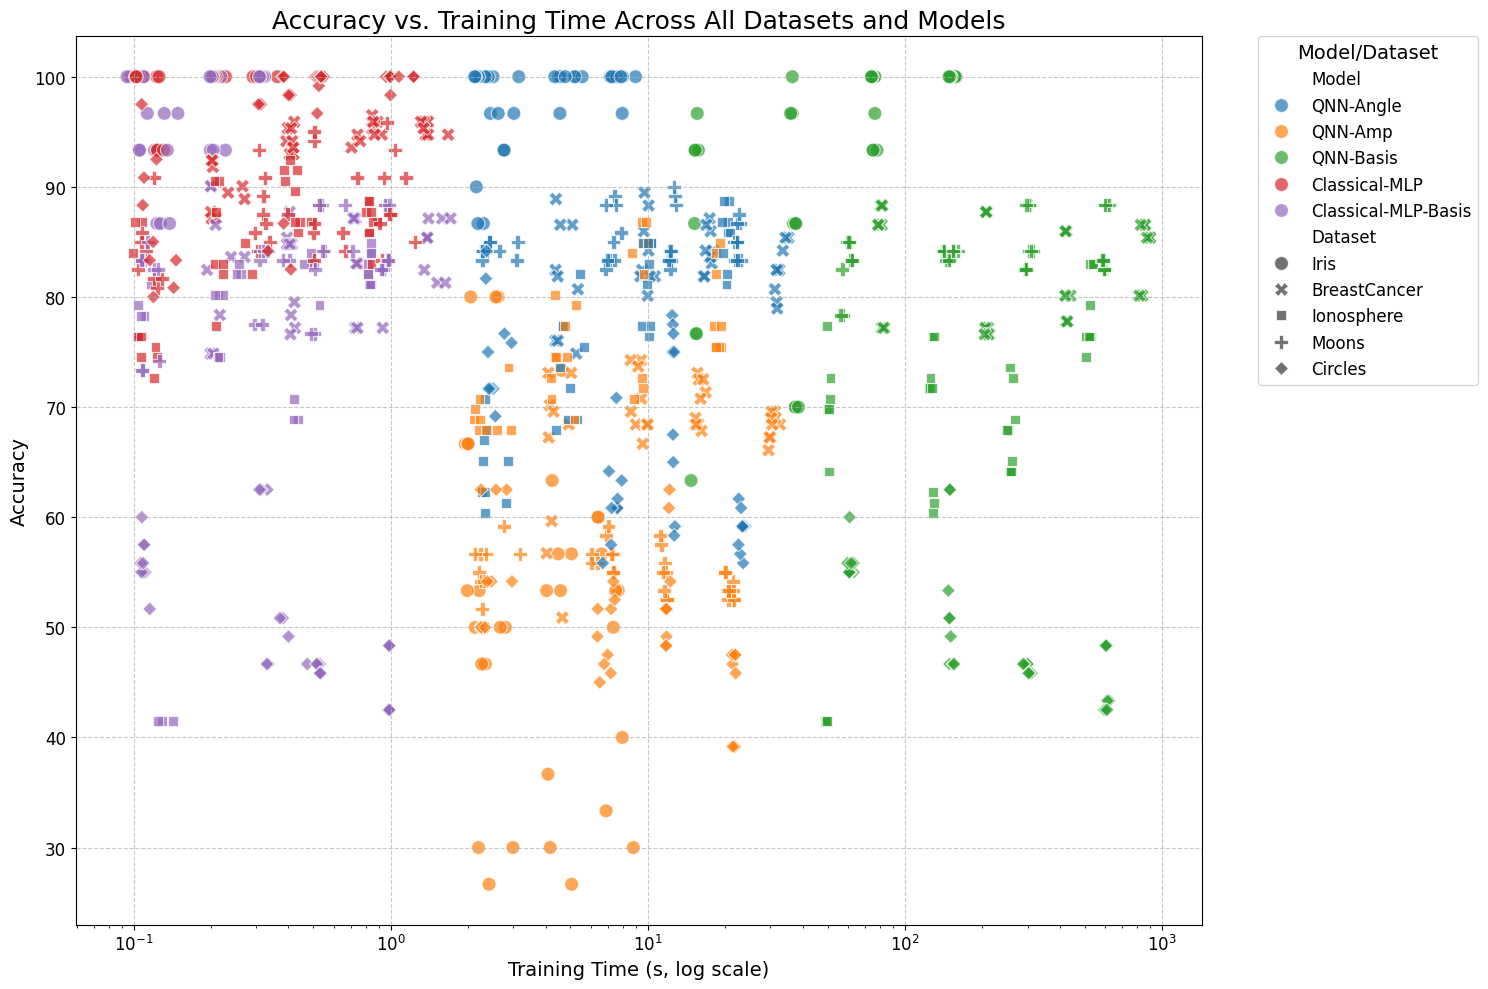

In [ ]:
fig = plt.figure(figsize=(15, 10))
sns.scatterplot(
    data=df_results,
    x='Training Time',
    y='Accuracy',
    hue='Model',
    style='Dataset',
    s=100, # size of points
    alpha=0.7 # transparency
)

plt.xscale('log') # Use log scale for training time to better visualize differences
plt.title('Accuracy vs. Training Time Across All Datasets and Models', fontsize=18)
plt.xlabel('Training Time (s, log scale)', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model/Dataset', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., fontsize=12, title_fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats

# Separate accuracy data for QNN and Classical-NN models
accuracy_qnn = df_qnn['Accuracy']
accuracy_classical = df_classical['Accuracy']

# Perform independent t-test
t_statistic, p_value = stats.ttest_ind(accuracy_qnn, accuracy_classical)

print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("\nThere is a statistically significant difference in accuracy between QNN and Classical-NN models (p < 0.05).")
else:
    print("\nThere is no statistically significant difference in accuracy between QNN and Classical-NN models (p >= 0.05).")

T-statistic: nan
P-value: nan

There is no statistically significant difference in accuracy between QNN and Classical-NN models (p >= 0.05).


# New section

In [ ]:
import os
import pandas as pd
from scipy import stats

# Load the recovered results file
csv_file = "ejmca_revised_results.csv"
if os.path.exists(csv_file):
    df_results = pd.read_csv(csv_file)
    df_results = df_results.rename(columns={
        "Fraction": "Training Fraction",
        "acc": "Accuracy",
        "time": "Training Time"
    })

    # Pivot the results to compare QNN-Basis and Classical-MLP-Basis directly
    pivot_df = df_results.pivot_table(
        index=['Dataset', 'Training Fraction', 'Split', 'InitSeed'],
        columns='Model',
        values='Accuracy'
    ).dropna(subset=['QNN-Basis', 'Classical-MLP-Basis'])

    # Extract the accuracies
    acc_qnn_basis = pivot_df['QNN-Basis']
    acc_mlp_basis = pivot_df['Classical-MLP-Basis']

    # Perform a paired t-test
    t_stat, p_val = stats.ttest_rel(acc_qnn_basis, acc_mlp_basis)

    print(f"Paired t-test between QNN-Basis and Classical-MLP-Basis (N = {len(pivot_df)} pairs):")
    print(f"QNN-Basis Mean Accuracy: {acc_qnn_basis.mean():.4f}%")
    print(f"Classical-MLP-Basis Mean Accuracy: {acc_mlp_basis.mean():.4f}%")
    print(f"Mean Difference (QNN - MLP): {(acc_qnn_basis.mean() - acc_mlp_basis.mean()):.4f}%")
    print(f"T-statistic: {t_stat:.4f}")
    print(f"P-value: {p_val:.4e}")

    if p_val < 0.05:
        print("\nResult: The difference is statistically significant (p < 0.05).")
    else:
        print("\nResult: The difference is NOT statistically significant (p >= 0.05).")
else:
    print(f"Error: '{csv_file}' not found.")

Paired t-test between QNN-Basis and Classical-MLP-Basis (N = 18 pairs):
QNN-Basis Mean Accuracy: 56.8713%
Classical-MLP-Basis Mean Accuracy: 55.8155%
Mean Difference (QNN - MLP): 1.0559%
T-statistic: 0.5867
P-value: 5.6514e-01

Result: The difference is NOT statistically significant (p >= 0.05).


In [ ]:
import os
from google.colab import files

# List files in the workspace to confirm they are there
files_in_dir = os.listdir('.')
target_files = ['ejmca_revised_results.csv', 'table1_formatted.csv']

print("Current Directory Files:", files_in_dir)
for f in target_files:
    if f in files_in_dir:
        print(f"Downloading {f}...")
        files.download(f)
    else:
        print(f"Could not find '{f}' in the current working directory. Check if the benchmark has finished running.")

Current Directory Files: ['.config', 'sample_data']
Could not find 'ejmca_revised_results.csv' in the current working directory. Check if the benchmark has finished running.
Could not find 'table1_formatted.csv' in the current working directory. Check if the benchmark has finished running.
